# D08. Kiểm thử DBSCAN của nhóm trên dữ liệu n chiều

*Dữ liệu mô phỏng, không phải dữ liệu ngân hàng thật. DBSCAN của nhóm nằm ở `src/clustering/dbscan.py`, bản gia tăng ở `src/clustering/incremental_dbscan.py`; DBSCAN của sklearn chỉ dùng để đối chiếu và nằm ở `baseline/`.*

**Mục tiêu.** Xem DBSCAN tự cài có chạy đúng trên dữ liệu 4 và 5 chiều không, tức là không viết cứng cho 2 cột `x`, `y`. Hình 2D chỉ dùng để vẽ. Notebook phục vụ mục 2.2 của yêu cầu đồ án (so với thư viện trên nhiều bộ dữ liệu) cho phần `fit` (mục 1 đến 4) và cho insert, delete (mục 5); phần nhiều chiều là làm thêm, yêu cầu chỉ bắt buộc 2D.

**Tương đương nghĩa là** mọi điểm có cùng loại (lõi, biên, nhiễu) và các điểm lõi được chia cụm giống sklearn. Điểm biên được phép khác cụm nếu nó mơ hồ: trong Eps có lõi của từ hai cụm trở lên, và cụm được gán là một trong số đó.

---
#### **0. THƯ VIỆN VÀ ĐƯỜNG DẪN**

In [1]:
## Thư viện và thư mục gốc repo
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def repo_root(start=None):
    """Thư mục gốc repo: đi ngược từ thư mục hiện tại đến nơi có src/preprocessing (chạy từ gốc repo hay từ notebooks/ đều được)."""
    here = Path(start or Path.cwd()).resolve()
    for d in (here, *here.parents):
        if (d / 'src' / 'preprocessing').is_dir():
            return d
    raise FileNotFoundError('không thấy src/preprocessing: hãy mở notebook bên trong repo')


ROOT = repo_root()
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
print(ROOT.name)

INCREMENTAL_DBSCAN_NHOM_1


In [2]:
## DBSCAN của nhóm, bộ khoảng cách, bộ vẽ và phần so sánh với sklearn
from src.clustering.dbscan import DBSCAN
from src.core.distance import DistanceMetric
from src.visualization import ClusterVisualizer, make_snapshot, project_2d, snapshot_from_model
from baseline.sklearn_dbscan import PointType, fit_full_dbscan
from baseline.static_equivalence import compare_static_fit, run_all
pd.set_option('display.width', 200); pd.set_option('display.max_columns', None); pd.set_option('display.max_rows', 100); pd.set_option('display.max_colwidth', 80)

---
#### **1. KHOẢNG CÁCH KHÔNG VIẾT CỨNG 2 CHIỀU**

In [3]:
## Hai vector 5 chiều: DistanceMetric của nhóm và numpy phải cho cùng kết quả
a = np.array([0.5, -1.2, 3.0, 0.0, 2.2]); b = np.array([1.5, 0.8, -1.0, 0.3, 2.0])
print(DistanceMetric.euclidean(a, b), np.linalg.norm(a - b))

4.596737973824482 4.596737973824482


In [4]:
## Sai số tuyệt đối giữa hai cách tính
abs(DistanceMetric.euclidean(a, b) - np.linalg.norm(a - b))

np.float64(0.0)

In [5]:
## Truy vấn lân cận trong 8 chiều: tập láng giềng của DBSCAN của nhóm phải trùng với cách tính bằng numpy
rng = np.random.default_rng(8)
P = rng.normal(size=(120, 8))
dist = np.linalg.norm(P[:, None, :] - P[None, :, :], axis=2)
eps8 = float(np.quantile(dist[np.triu_indices(len(P), 1)], 0.05))
m8 = DBSCAN(eps8, 4).fit(P)
khop = [set(m8._region_query(i)) == set(np.where(dist[i] <= eps8)[0]) for i in range(len(P))]
print('Eps = %.3f | số điểm có tập láng giềng khớp numpy: %d / %d' % (eps8, sum(khop), len(P)))

Eps = 2.403 | số điểm có tập láng giềng khớp numpy: 120 / 120


In [6]:
## neighbor_ids lưu sẵn ở từng điểm cũng phải khớp numpy (bản tăng dần sẽ cập nhật phần này)
khop_cache = [m8.points[i].neighbor_ids == set(np.where(dist[i] <= eps8)[0]) for i in range(len(P))]
print('số điểm có neighbor_ids khớp numpy: %d / %d' % (sum(khop_cache), len(P)))

số điểm có neighbor_ids khớp numpy: 120 / 120


---
#### **2. MỘT BỘ 5 CHIỀU, TỪNG BƯỚC**

In [7]:
## Đọc bảng thẻ đã làm sạch và chuẩn hóa (D02): năm cột đặc trưng kết thúc bằng _z
card = pd.read_csv('data/processed/card_txn_5d_scaled.csv', encoding='utf-8')
feature_cols = [c for c in card.columns if c.endswith('_z')]
X = card[feature_cols].to_numpy()
print(X.shape, feature_cols)

(1492, 5) ['log10_amount_vnd_z', 'hour_of_day_z', 'distance_from_home_km_z', 'txns_last_7d_z', 'merchant_risk_score_z']


In [8]:
## Năm dòng đầu của ma trận đặc trưng
card[['txn_id'] + feature_cols].head()

,txn_id,log10_amount_vnd_z,hour_of_day_z,distance_from_home_km_z,txns_last_7d_z,merchant_risk_score_z
0,TXN001280,-0.443715,0.046964,-0.202115,0.040859,-0.659513
1,TXN001099,0.288938,1.487087,-0.311217,-0.675968,-0.101941
2,TXN000267,-0.329250,-0.036006,-0.267364,-0.138348,-1.254887
3,TXN000506,-1.355461,-1.738373,-0.193805,1.295307,1.462096
4,TXN001297,-1.236008,-1.510206,-0.189030,1.295307,1.684179


In [9]:
## Fit DBSCAN của nhóm với Eps = 0.65, MinPts = 10 (tham số của bảng thẻ trong data card)
model = DBSCAN(0.65, 10).fit(X)
labels = np.array(model.get_labels())
print('cụm:', len(set(labels) - {-1}), '| nhiễu:', int((labels == -1).sum()), '| điểm lõi:', sum(p.is_core for p in model.points.values()))

cụm: 4 | nhiễu: 19 | điểm lõi: 1472


In [10]:
## Cùng dữ liệu, cùng tham số với DBSCAN của sklearn (baseline)
sk_labels, sk_types = fit_full_dbscan(X, 0.65, 10)
print('cụm:', len(set(sk_labels) - {-1}), '| nhiễu:', int((sk_labels == -1).sum()), '| điểm lõi:', int((sk_types == int(PointType.CORE)).sum()))

cụm: 4 | nhiễu: 19 | điểm lõi: 1472


In [11]:
## So sánh theo tiêu chí tương đương (loại điểm, phân hoạch lõi, điểm biên mơ hồ); thời gian là một lần đo
compare_static_fit(DBSCAN, X, 0.65, 10)

{'n': 1492,
 'dims': 5,
 'clusters_engine': 4,
 'clusters_sklearn': 4,
 'types_equal': True,
 'cores_equal': True,
 'noise_equal': True,
 'core_partition_ari': 1.0,
 'border_diff': 0,
 'border_diff_all_ambiguous': True,
 'engine_seconds': 4.111,
 'sklearn_seconds': 0.0129,
 'equivalent': True}

In [12]:
## Đối chiếu với nhãn thật của bộ sinh dữ liệu (segment_id, -1 là bất thường): mỗi nhóm thật nằm gọn trong một cụm
pd.crosstab(card['segment_id'], labels, rownames=['segment_id'], colnames=['cụm của nhóm'])

cụm của nhóm,-1,0,1,2,3
segment_id,,,,,
-1,15,0,0,0,0
0,1,560,0,0,0
1,0,0,414,0,0
2,1,0,0,0,235
3,2,0,0,264,0


---
#### **3. HÌNH 2D CỦA BỘ 5 CHIỀU (PCA CHỈ ĐỂ VẼ)**

phương sai giữ lại bởi hai thành phần PCA: 76.0 %


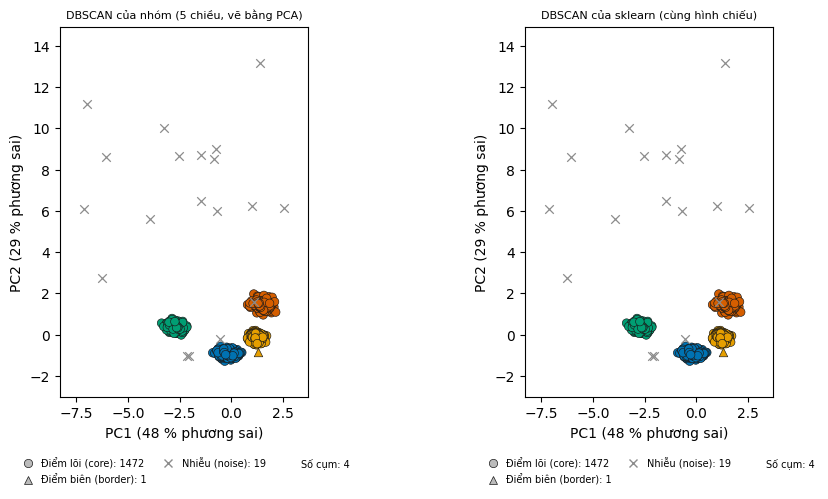

In [13]:
## Chiếu 5 chiều xuống 2 bằng PCA tự viết, rồi vẽ kết quả của nhóm và của sklearn cạnh nhau
proj, explained = project_2d(X)
viz = ClusterVisualizer()
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
trucs = (f'PC1 ({100 * explained[0]:.0f} % phương sai)', f'PC2 ({100 * explained[1]:.0f} % phương sai)')
viz.plot_2d(make_snapshot(range(len(X)), proj, labels, [model.points[i].point_type for i in range(len(X))]), ax=axes[0], title='DBSCAN của nhóm (5 chiều, vẽ bằng PCA)', axis_labels=trucs)
viz.plot_2d(make_snapshot(range(len(X)), proj, sk_labels, sk_types), ax=axes[1], title='DBSCAN của sklearn (cùng hình chiếu)', axis_labels=trucs)
print('phương sai giữ lại bởi hai thành phần PCA: %.1f %%' % (100 * explained.sum()))
plt.show()

---
#### **4. TOÀN BỘ CÁC TRƯỜNG HỢP**

In [14]:
## Chạy DBSCAN của nhóm trên mọi trường hợp: toy, toy_edge (đầu và cuối), bốn bảng dữ liệu và D0 của ba stream
report = run_all(DBSCAN)
print(len(report), 'trường hợp')

62 trường hợp


In [15]:
## Bảng đủ 62 trường hợp (2, 4 và 5 chiều)
report[['case', 'dims', 'n', 'clusters_engine', 'clusters_sklearn', 'types_equal', 'core_partition_ari', 'border_diff', 'equivalent']]

,case,dims,n,clusters_engine,clusters_sklearn,types_equal,core_partition_ari,border_diff,equivalent
0,toy/r02_1_noise (đầu),2,6,1,1,True,1.0,0,True
1,toy/r02_1_noise (cuối),2,7,1,1,True,1.0,0,True
2,toy/r02_2_creation (đầu),2,3,0,0,True,1.0,0,True
3,toy/r02_2_creation (cuối),2,4,1,1,True,1.0,0,True
4,toy/r02_3_absorption (đầu),2,6,1,1,True,1.0,0,True
5,toy/r02_3_absorption (cuối),2,7,1,1,True,1.0,0,True
6,toy/r02_4_merge (đầu),2,12,2,2,True,1.0,0,True
7,toy/r02_4_merge (cuối),2,13,1,1,True,1.0,0,True
8,toy/r03_1_removal (đầu),2,5,1,1,True,1.0,0,True
9,toy/r03_1_removal (cuối),2,4,0,0,True,1.0,0,True


In [16]:
## Tóm tắt theo số chiều
report.groupby('dims').agg(so_truong_hop=('case', 'count'), tuong_duong=('equivalent', 'sum'), so_diem_toi_da=('n', 'max'))

,so_truong_hop,tuong_duong,so_diem_toi_da
dims,,,
2,55,55,2000
4,2,2,14
5,5,5,1592


In [17]:
## Các bảng lớn: thời gian fit của bản Python thuần so với sklearn (một lần đo mỗi bên, không phải benchmark)
big = report[report['n'] >= 500][['case', 'dims', 'n', 'engine_seconds', 'sklearn_seconds']].copy()
big['cham_hon_sklearn'] = (big['engine_seconds'] / big['sklearn_seconds']).round().astype(int)
print('tổng số điểm biên khác cụm trên 62 trường hợp:', int(report['border_diff'].sum()))
big

tổng số điểm biên khác cụm trên 62 trường hợp: 0


,case,dims,n,engine_seconds,sklearn_seconds,cham_hon_sklearn
54,atm_txn_2d,2,1200,2.165,0.0028,773
55,atm_txn_2d_hard,2,2000,8.990,0.0084,1070
56,card_txn_5d_scaled,5,1492,4.861,0.0160,304
57,card_txn_5d_hard_scaled,5,1592,5.133,0.0085,604
58,blobs5d_n860_scaled,5,860,1.474,0.0043,343
59,bank_geo/atm_stream D0,2,529,0.344,0.0012,287
60,bank_card/card_stream D0,5,500,0.413,0.0023,180
61,bank_card/card_stream_hard D0,5,500,0.410,0.0015,273


In [18]:
## Kết luận phải là True: mọi trường hợp tương đương sklearn
bool(report['equivalent'].all())

True

---
#### **5. INSERT VÀ DELETE TRONG 5 CHIỀU**

*Phần này chạy `IncrementalDBSCAN` của nhóm (qua `IncrementalEngine`, chỉ thêm `snapshot()`) trên hai luồng thẻ 5 chiều. Sau mỗi update, trạng thái của bản gia tăng được so với sklearn fit lại trên cùng tập điểm.*

In [19]:
## Bản gia tăng của nhóm và hàm so hai snapshot của D05, D06
from src.experiments.engine import IncrementalEngine
from baseline.sklearn_dbscan import RefitDBSCAN, ambiguous_by_step, read_stream
from baseline.update_experiments import snapshots_equivalent
from src.visualization import stream_snapshots

In [20]:
## Chạy hết hai luồng thẻ (mỗi luồng 300 update: chèn giao dịch mới, xóa giao dịch cũ nhất) và so từng step với sklearn
ket_qua = []
for ten in ('card_stream', 'card_stream_hard'):
    thu_muc = f'data/raw/bank_card/{ten}'
    d0, upd, params, feats = read_stream(thu_muc)
    mo_ho = ambiguous_by_step(params, upd)
    gia_tang, sk = stream_snapshots(IncrementalEngine, thu_muc), stream_snapshots(RefitDBSCAN, thu_muc)
    khop = [snapshots_equivalent(a['snapshot'], b['snapshot'], params['eps'], mo_ho.get(a['step'], [])) for a, b in zip(gia_tang, sk)]
    ket_qua.append({'luong': ten, 'so_chieu': len(feats), 'eps': params['eps'], 'minpts': params['minpts'], 'fit_D0_tuong_duong': khop[0], 'so_update': len(khop) - 1,
                    'update_tuong_duong': sum(khop[1:]), 'so_cum_cuoi': len(set(gia_tang[-1]['snapshot']['labels'].tolist()) - {-1})})
pd.DataFrame(ket_qua)

,luong,so_chieu,eps,minpts,fit_D0_tuong_duong,so_update,update_tuong_duong,so_cum_cuoi
0,card_stream,5,0.4,6,True,300,300,4
1,card_stream_hard,5,0.3,6,True,300,300,4


In [21]:
## Sau 300 update, neighbor_ids của từng điểm vẫn phải khớp lân cận tính lại bằng numpy (insert và delete đều sửa bộ nhớ đệm này)
mo_hinh = IncrementalEngine(params['eps'], params['minpts'])
from src.preprocessing.stream_scaling import stream_coordinates
mo_hinh.fit(stream_coordinates(params, d0, feats))
anh_xa = dict(zip(d0['point_id'], range(len(d0))))
xs = stream_coordinates(params, upd, feats)
for k, r in enumerate(upd.itertuples()):
    if r.op == 'insert':
        anh_xa[r.point_id] = mo_hinh.insert(xs[k])
    else:
        mo_hinh.delete(anh_xa.pop(r.point_id))
ids = sorted(mo_hinh.points)
Xc = np.vstack([mo_hinh.points[i].coords for i in ids])
D = np.linalg.norm(Xc[:, None, :] - Xc[None, :, :], axis=2)
khop_cache = [mo_hinh.points[i].neighbor_ids == {ids[j] for j in np.where(D[k] <= params['eps'])[0]} for k, i in enumerate(ids)]
print('card_stream_hard sau 300 update: %d điểm, neighbor_ids khớp numpy ở %d / %d điểm' % (len(ids), sum(khop_cache), len(ids)))

card_stream_hard sau 300 update: 500 điểm, neighbor_ids khớp numpy ở 500 / 500 điểm


---
#### **6. KẾT LUẬN**

- `DBSCAN.fit` của nhóm cho kết quả giống sklearn ở cả 62 trường hợp: cùng loại điểm, cùng cách chia cụm, không có điểm biên nào lệch. Trong đó có bộ 4 chiều (`toy_edge/e18`) và các bộ 5 chiều (bảng thẻ dễ và khó, blobs của D01, D0 của hai luồng thẻ).
- Khoảng cách, truy vấn lân cận và `neighbor_ids` dùng hết các tọa độ nên chạy được với số chiều bất kỳ; hình 2D của dữ liệu nhiều chiều chỉ là phép chiếu PCA.
- Bản Python của nhóm chậm hơn sklearn khoảng 170 đến 1.300 lần trên các bảng lớn (mục 4, mỗi bên đo một lần). sklearn viết phần lõi bằng Cython và dùng cây chỉ mục để tìm lân cận, còn bản của nhóm tính khoảng cách từng cặp bằng vòng lặp Python. Vì vậy muốn biết bản tăng dần nhanh hơn bao nhiêu thì phải so với chính DBSCAN của nhóm fit lại (D09).
- `IncrementalDBSCAN` của nhóm cũng chạy đúng trong 5 chiều: qua 600 update của hai luồng thẻ, mọi step đều tương đương sklearn fit lại, và bộ nhớ đệm `neighbor_ids` vẫn khớp lân cận tính lại bằng numpy sau 300 update (mục 5). Phần thí nghiệm chèn, xóa chi tiết ở D05, D06.

**Đối chiếu với tiêu chí D08 trong bảng phân công**

| Tiêu chí | Bằng chứng trong notebook và repo |
|---|---|
| Chạy thuật toán trên ít nhất 4 chiều | mục 2 và 4: 4 chiều (`toy_edge/e18`) và 5 chiều (bảng thẻ dễ và khó, blobs của D01, D0 hai luồng thẻ) đều tương đương sklearn |
| Distance và region query không phụ thuộc 2D | mục 1: khoảng cách 5 chiều khớp numpy; truy vấn lân cận và bộ nhớ đệm `neighbor_ids` trong 8 chiều khớp numpy ở mọi điểm |
| Trực quan chỉ lấy 2 feature hoặc projection | mục 3: PCA tự viết (`project_2d`), chỉ dùng để vẽ |
| Đầu ra: n-D test và bảng kết quả | `tests/tv4/test_real_dbscan_equivalence.py` (62 trường hợp, lân cận trong 2, 5 và 8 chiều, ba engine cố ý sai để chắc bộ so sánh bắt được lỗi) và bảng ở mục 4 |
| Insert và delete trong n chiều | mục 5: hai luồng thẻ 5 chiều, 600 update, mọi step tương đương sklearn; `tests/tv4/test_incremental_experiments.py` |
| PASS: logic gom cụm chạy n-D, 2D chỉ là lớp trực quan | đạt |